# Insurance Risk Project

## Imports

In [78]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
from plotly import graph_objects as go
from plotly.subplots import make_subplots
import seaborn as sns
import matplotlib.pyplot as plt
import time
import shap
import joblib

pd.set_option('display.max_columns', None)

In [215]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, TargetEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_score, recall_score, f1_score
from sklearn.calibration import calibration_curve

In [53]:
from xgboost import XGBClassifier

## Data Source

In [3]:
# descargar desde kagglehub
file_path = "train.csv"

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "ifteshanajnin/carinsuranceclaimprediction-classification",
  file_path,
)


In [4]:
df.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


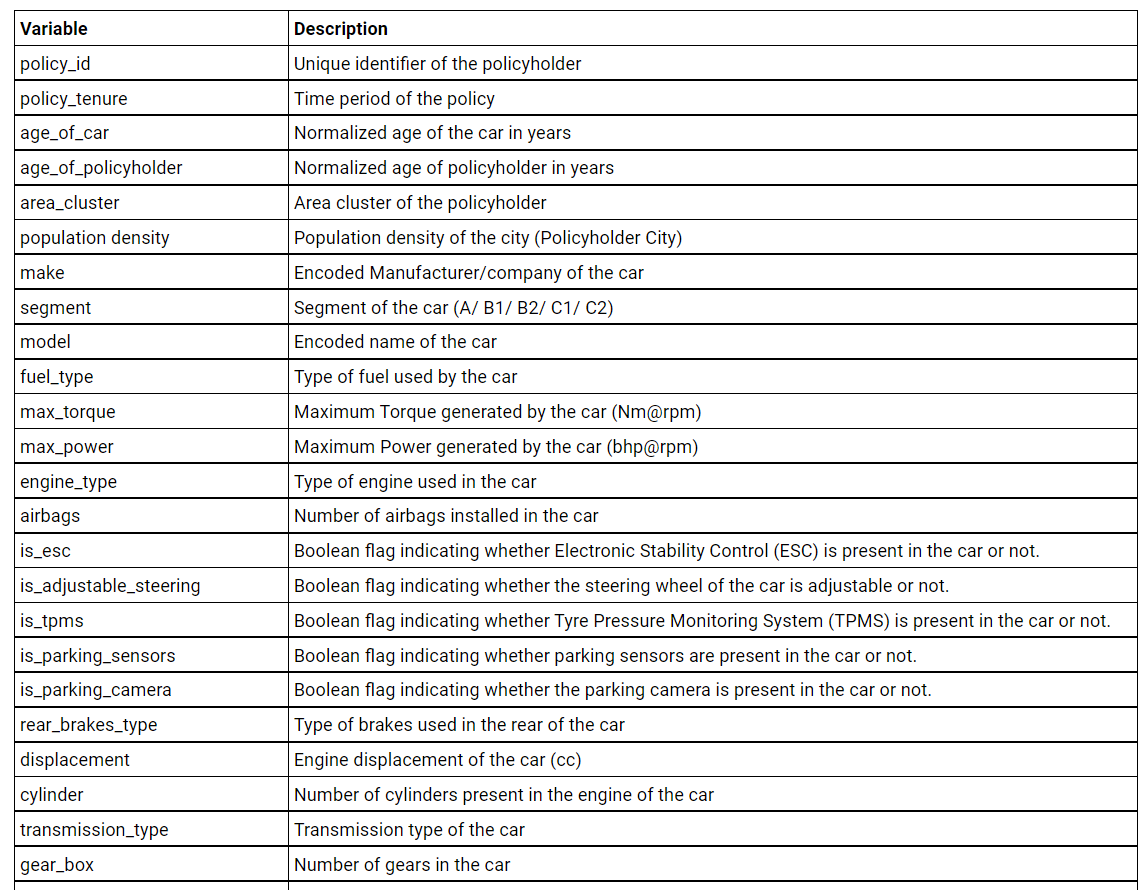

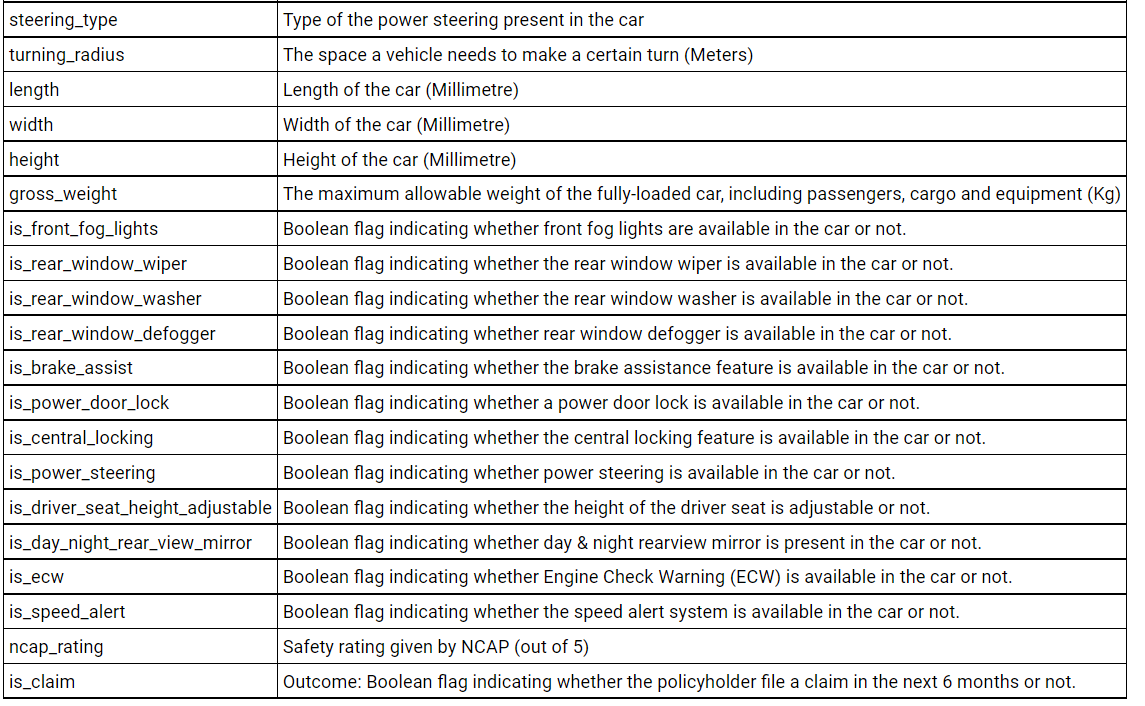

In [5]:
# esquema
from IPython.display import Image, display

display(Image("../external_info/schema.png"))
display(Image("../external_info/schema_2.png"))

## Data Preparation

### Limpieza General

In [6]:
# drop de columnas correlacionadas

df = df.drop(
    columns=[
        'airbags',
        'displacement',
        'cylinder',
        'gear_box',
        'turning_radius',
        'length',
        'width',
        'height',
    ]
)

In [7]:
# parseo numerico de max_torque y max_power
df['max_torque'] = df['max_torque'].str.split('Nm').str[0]
df['max_torque'] = df['max_torque'].astype(float)

df['max_power'] = df['max_power'].str.split('bhp').str[0]
df['max_power'] = df['max_power'].astype(float)

In [26]:
# convertir make en str ya que es una etiqueta del fabricante
df['make'] = df['make'].astype(str)

### Train Test Split

In [30]:
X = df.drop(columns=['policy_id', 'is_claim'])
y = df['is_claim']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test,y_test, test_size=0.5, random_state=42)

In [31]:
len(X_test) + len(X_val) == round(len(X) * 0.3)

True

### Numerical Pipeline

In [10]:
# pipeline numerico sin tomar en cuenta car_age y age_of_policyholder
numeric_pipe = Pipeline([
    ('scaler', StandardScaler())
])

numeric_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### Categorical Pipeline

In [11]:
# pipeline para columnas con mayor cardinalidad
# area_cluster, engine_type, model

cat_pipe_1 = Pipeline([
    ('target_encoder', TargetEncoder())
])

cat_pipe_1

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('target_encoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"categories categories: ""auto"" or list of shape (n_features,) of array-like, default=""auto""Categories (unique values) per feature:- `""auto""` : Determine categories automatically from the training data.- list : `categories[i]` holds the categories expected in the i-th column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories are stored in the `categories_` fitted attribute.",'auto'
,"target_type target_type: {""auto"", ""continuous"", ""binary"", ""multiclass""}, default=""auto""Type of target.- `""auto""` : Type of target is inferred with :func:`~sklearn.utils.multiclass.type_of_target`.- `""continuous""` : Continuous target- `""binary""` : Binary target- `""multiclass""` : Multiclass target.. note:: The type of target inferred with `""auto""` may not be the desired target type used for modeling. For example, if the target consisted of integers between 0 and 100, then :func:`~sklearn.utils.multiclass.type_of_target` will infer the target as `""multiclass""`. In this case, setting `target_type=""continuous""` will specify the target as a regression problem. The `target_type_` attribute gives the target type used by the encoder... versionchanged:: 1.4 Added the option 'multiclass'.",'auto'
,"smooth smooth: ""auto"" or float, default=""auto""The amount of mixing of the target mean conditioned on the value of thecategory with the global target mean. A larger `smooth` value will putmore weight on the global target mean.If `""auto""`, then `smooth` is set to an empirical Bayes estimate.",'auto'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the splitting strategy used in the internal :term:`cross fitting`during :meth:`fit_transform`. Splitters where each sample index doesn't appearin the validation fold exactly once, raise a `ValueError`.Possible inputs for cv are:- `None`, to use a 5-fold cross-validation chosen internally based on `target_type`,- integer, to specify the number of folds for the cross-validation chosen internally based on `target_type`,- :term:`CV splitt

In [12]:
# pipeline para resto de columnas
cat_pipe_2 = Pipeline([
    ('one_hot_encoder', OneHotEncoder(handle_unknown='ignore', drop='if_binary'))
])
cat_pipe_2

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('one_hot_encoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",'if_binary'
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` categor

### All Together

In [44]:
# colocar todo junto en un column transformer
cardinal_columns = ['area_cluster', 'engine_type', 'model']
cat_columns = X_train.select_dtypes(include=str).columns.drop(cardinal_columns)
numeric_cols = X_train.select_dtypes(include=np.number).columns.drop(['age_of_car', 'age_of_policyholder'])

preprocessing = ColumnTransformer([
    ('num_transformer', numeric_pipe, numeric_cols),
    ('cat_transformer_1',cat_pipe_1, cardinal_columns),
    ('cat_transformer_2', cat_pipe_2, cat_columns)
], remainder='passthrough')

preprocessing


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_transformer', ...), ('cat_transformer_1', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``t

### Fit Transform (solo para visualizar df procesado)

In [ ]:
# solo para ver el output
X_train_transformed = preprocessing.fit_transform(X_train, y_train)

X_train_transformed = pd.DataFrame(
    X_train_transformed, 
    columns=preprocessing.get_feature_names_out()
)

X_train_transformed

,num_transformer__policy_tenure,num_transformer__population_density,num_transformer__max_torque,num_transformer__max_power,num_transformer__gross_weight,num_transformer__ncap_rating,cat_transformer_1__area_cluster,cat_transformer_1__engine_type,cat_transformer_1__model,cat_transformer_2__make_1,cat_transformer_2__make_2,cat_transformer_2__make_3,cat_transformer_2__make_4,cat_transformer_2__make_5,cat_transformer_2__segment_A,cat_transformer_2__segment_B1,cat_transformer_2__segment_B2,cat_transformer_2__segment_C1,cat_transformer_2__segment_C2,cat_transformer_2__segment_Utility,cat_transformer_2__fuel_type_CNG,cat_transformer_2__fuel_type_Diesel,cat_transformer_2__fuel_type_Petrol,cat_transformer_2__is_esc_Yes,cat_transformer_2__is_adjustable_steering_Yes,cat_transformer_2__is_tpms_Yes,cat_transformer_2__is_parking_sensors_Yes,cat_transformer_2__is_parking_camera_Yes,cat_transformer_2__rear_brakes_type_Drum,cat_transformer_2__transmission_type_Manual,cat_transformer_2__steering_type_Electric,cat_transformer_2__steering_type_Manual,cat_transformer_2__steering_type_Power,cat_transformer_2__is_front_fog_lights_Yes,cat_transformer_2__is_rear_window_wiper_Yes,cat_transformer_2__is_rear_window_washer_Yes,cat_transformer_2__is_rear_window_defogger_Yes,cat_transformer_2__is_brake_assist_Yes,cat_transformer_2__is_power_door_locks_Yes,cat_transformer_2__is_central_locking_Yes,cat_transformer_2__is_power_steering_Yes,cat_transformer_2__is_driver_seat_height_adjustable_Yes,cat_transformer_2__is_day_night_rear_view_mirror_Yes,cat_transformer_2__is_ecw_Yes,cat_transformer_2__is_speed_alert_Yes,remainder__age_of_car,remainder__age_of_policyholder
0,0.874531,-0.569852,-0.294496,0.343311,-0.237399,0.168540,0.069042,0.066840,0.066840,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.07,0.384615
1,-0.249260,3.087387,1.579394,1.245252,1.576710,0.888292,0.044427,0.061936,0.061936,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.10,0.576923
2,1.176443,-0.761326,-0.294496,0.343311,-0.237399,0.168540,0.049060,0.066840,0.066840,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.07,0.432692
3,0.435756,-0.569852,-0.294496,0.343311,-0.237399,0.168540,0.070804,0.065474,0.065474,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.06,0.721154
4,-1.449424,0.898113,-0.294496,0.343311,-0.237399,0.168540,0.053893,0.065454,0.065454,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.01,0.403846
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41009,1.488363,-0.569852,1.579394,1.245252,1.576710,0.888292,0.070804,0.064921,0.064921,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.19,0.451923
41010,-0.404260,-0.836806,-1.019431,-1.396947,-0.944195,-1.270964,0.065881,0.062417,0.062417,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.00,0.519231
41011,1.392607,-0.569852,-0.294496,0.343311,-0.237399,0.168540,0.069042,0.066840,0.066840,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.13,0.326923
41012,-1.423264,0.898113,-1.019431,-1.396947,-0.944195,-1.270964,0.053858,0.060213,0.060213,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.

## Modeling

### 1. Random Forest

In [50]:
# pipeline 

rf_pipe = Pipeline([
    ('preprocessing', preprocessing),
    ('model', RandomForestClassifier(class_weight='balanced', random_state=42))
])

rf_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_transformer', ...), ('cat_transformer_1', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold spa

#### Cross Validation (baseline, sin tuning)

In [51]:
# mismos folds fijos para RF y XGBoost, para poder comparar sus scores directamente
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_baseline_scores = cross_val_score(
    rf_pipe, X_train, y_train,
    cv=cv, scoring='average_precision', n_jobs=-1
)

rf_baseline_scores.mean(), rf_baseline_scores.std()

(np.float64(0.08320168615508303), np.float64(0.0025396083165694344))

#### Grid Search

In [52]:

rf_param_grid = {
    'model__n_estimators': [200, 400],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_leaf': [1, 5, 10],
}

rf_grid = GridSearchCV(
    rf_pipe,
    param_grid=rf_param_grid,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
)

rf_grid.fit(X_train, y_train)

rf_grid.best_score_, rf_grid.best_params_

(np.float64(0.10216177013519127),
 {'model__max_depth': 10,
  'model__min_samples_leaf': 10,
  'model__n_estimators': 400})

### 2. XGBoost

In [183]:
(y_train == 1).sum() / len(y_train)

np.float64(0.06307602282147559)

In [58]:
# pipeline 
xgb_pipe = Pipeline([
    ('preprocessing', preprocessing),
    ('model', XGBClassifier(scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()))
    
])

xgb_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_transformer', ...), ('cat_transformer_1', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold spa

#### Cross Validation (baseline, sin tuning)

In [60]:
xgb_baseline_scores = cross_val_score(
    xgb_pipe, X_train, y_train, 
    cv=cv, scoring='average_precision', n_jobs=-1
)

xgb_baseline_scores.mean(), xgb_baseline_scores.std()

(np.float64(0.08446447554517178), np.float64(0.0020618134773596536))

#### Grid Search

In [62]:
xgb_param_grid = {
    'model__n_estimators': [200, 400],
    'model__max_depth': [3, 5, 7],
    'model__learning_rate': [0.05, 0.1],
}

xgb_grid = GridSearchCV(
    xgb_pipe,
    param_grid=xgb_param_grid,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1
    
)

xgb_grid.fit(X_train, y_train)

xgb_grid.best_score_, xgb_grid.best_params_

(np.float64(0.10123488960412239),
 {'model__learning_rate': 0.05,
  'model__max_depth': 3,
  'model__n_estimators': 200})

#### Models vs X_val

In [ ]:
# resultados para xval con random forest
# pr-auc requiere como argumentos la probabilidad de predecir clase positiva y el valor de y

model_rf = rf_grid.best_estimator_
start = time.perf_counter()
rf_proba = model_rf.predict_proba(X_val)[:,1]
elapsed = time.perf_counter() - start
rf_val_pr_auc =  average_precision_score(y_val, rf_proba)
inference_ms_per_1k = elapsed / len(X_val) * 1000 * 1000

print(f"""
      pr-auc en grid search: {rf_grid.best_score_}.   
      pr-auc en x val: {rf_val_pr_auc}.   
      inference_ms_per_1k: {inference_ms_per_1k}
      """)


      pr-auc en grid search: 0.10216177013519127.   
      pr-auc en x val: 0.12150566670938266.   
      inference_ms_per_1k: (37.169515871927274,)
      


In [ ]:
# resultados para xval con xgboost
# pr-auc requiere como argumentos la probabilidad de predecir clase positiva y el valor de y

model_xgb = xgb_grid.best_estimator_
start = time.perf_counter()
xgb_proba = model_xgb.predict_proba(X_val)[:,1]
elapsed = time.perf_counter() - start
xgb_val_pr_auc =  average_precision_score(y_val, xgb_proba)
inference_ms_per_1k = elapsed / len(X_val) * 1000 * 1000

print(f"""
      pr-auc en grid search: {xgb_grid.best_score_}.   
      pr-auc en x val: {xgb_val_pr_auc}.   
      inference_ms_per_1k: {inference_ms_per_1k}
      """)


      pr-auc en grid search: 0.10123488960412239.   
      pr-auc en x val: 0.11878628557231488.   
      inference_ms_per_1k: (9.491115826752582,)
      


#### XGBoost vs Test Set

In [72]:
claim_proba = model_xgb.predict_proba(X_test)[:,1]
final_pr_auc = average_precision_score(y_test, claim_proba)

print(f"""
      pr-auc en grid search: {xgb_grid.best_score_}.   
      pr-auc en x test: {final_pr_auc}.   
      """)


      pr-auc en grid search: 0.10123488960412239.   
      pr-auc en x test: 0.09705080004686165.   
      


In [80]:
# guardado de modelo
joblib.dump(model_xgb, '../models/xgb_pipeline.joblib')

['../models/xgb_pipeline.joblib']

## SHAP (Entender el modelo)

### 1. Separar preprocessing y modelo
SHAP (`TreeExplainer`) necesita el modelo XGBoost solo, no el Pipeline completo. Transformamos `X_test` con el preprocessor ya entrenado (`transform`, no `fit_transform`) para que SHAP vea exactamente lo mismo que ve el modelo.

In [74]:
# shap necesita el modelo xgboost "desnudo", no el pipeline completo
preprocessor = model_xgb.named_steps['preprocessing']
xgb_model = model_xgb.named_steps['model']

# transformamos X_test igual que lo ve el modelo por dentro (sin volver a fitear)
X_test_transformed = preprocessor.transform(X_test)
if hasattr(X_test_transformed, 'toarray'):      # por si ColumnTransformer devolvio matriz sparse
    X_test_transformed = X_test_transformed.toarray()

# nombres de las columnas ya transformadas (el OneHotEncoder expandio columnas)
feature_names = preprocessor.get_feature_names_out()

X_test_transformed = pd.DataFrame(
    X_test_transformed, columns=feature_names, index=X_test.index
).astype(float)

X_test_transformed.shape

(8789, 47)

### 2. Explainer y chequeo de aditividad
Para cada póliza: **valor base + suma de contribuciones SHAP = score del modelo en log-odds**. Si el chequeo da `True`, SHAP está explicando exactamente al modelo.

In [ ]:
# pasar el modelo a shap
explainer = shap.TreeExplainer(xgb_model)

# pasar X test transformado
# shap_values es un objeto que contiene valores (empujones de cada columna), valores base, copia de X_test transformed y nombres de col
# tanto, los valores, como los valores base y la copia de X_test transformed vienen por poliza
shap_values = explainer(X_test_transformed)

# chequeo: valor base + suma de contribuciones == log-odds que da el modelo (para cada poliza)
reconstructed = shap_values.base_values + shap_values.values.sum(axis=1) # suma de todos los valores (valor por columna) en cada poliza
model_margin = xgb_model.predict(X_test_transformed, output_margin=True)   # log-odds, no probabilidad

np.allclose(reconstructed, model_margin, atol=1e-4)

True

In [141]:
shap_values.values.shape

(8789, 47)

### 3. Explicación global
- **Bar plot**: importancia promedio de cada variable = promedio de |SHAP| sobre todas las pólizas (cuánto mueve el score, sin importar la dirección).
- **Beeswarm**: cada punto es una póliza. Eje X = contribución SHAP (derecha = empuja hacia siniestro). Color = valor de la variable (rojo alto, azul bajo).

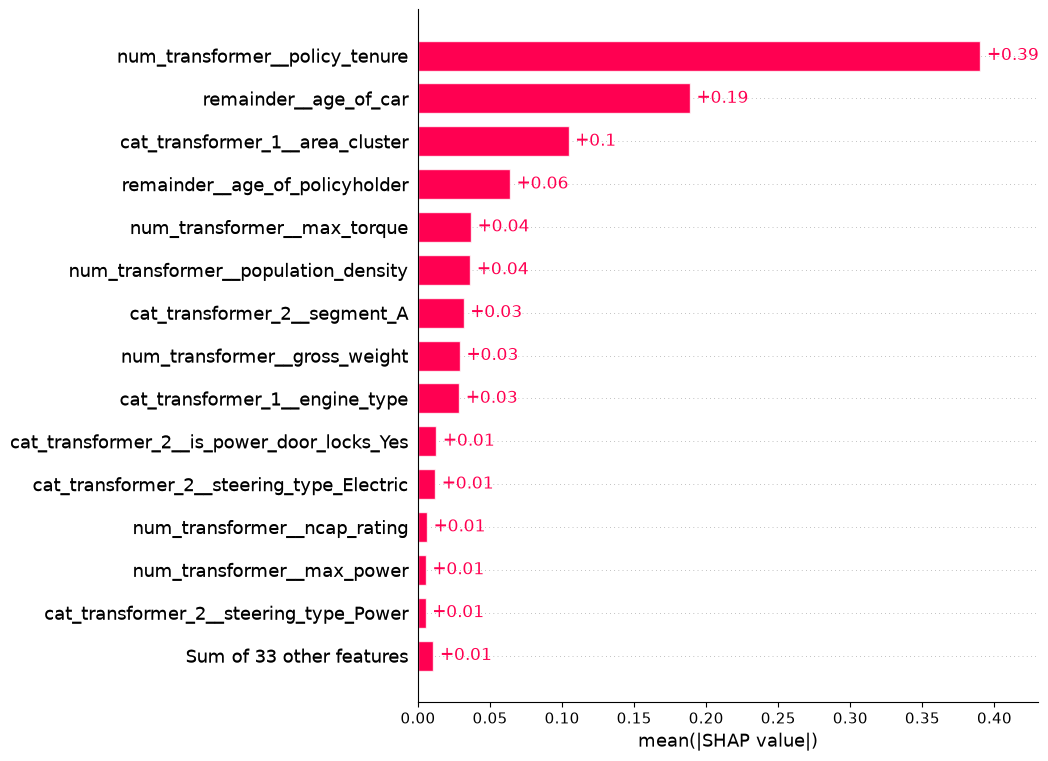

In [ ]:
# ranking de importancia: promedio de |shap| por variable
# por cada poliza obtienes el .value absoulto, si sacas el promedio de cada una es este valor
# solo tienes que llamar el metodo plots con los shap values
shap.plots.bar(shap_values, max_display=15)

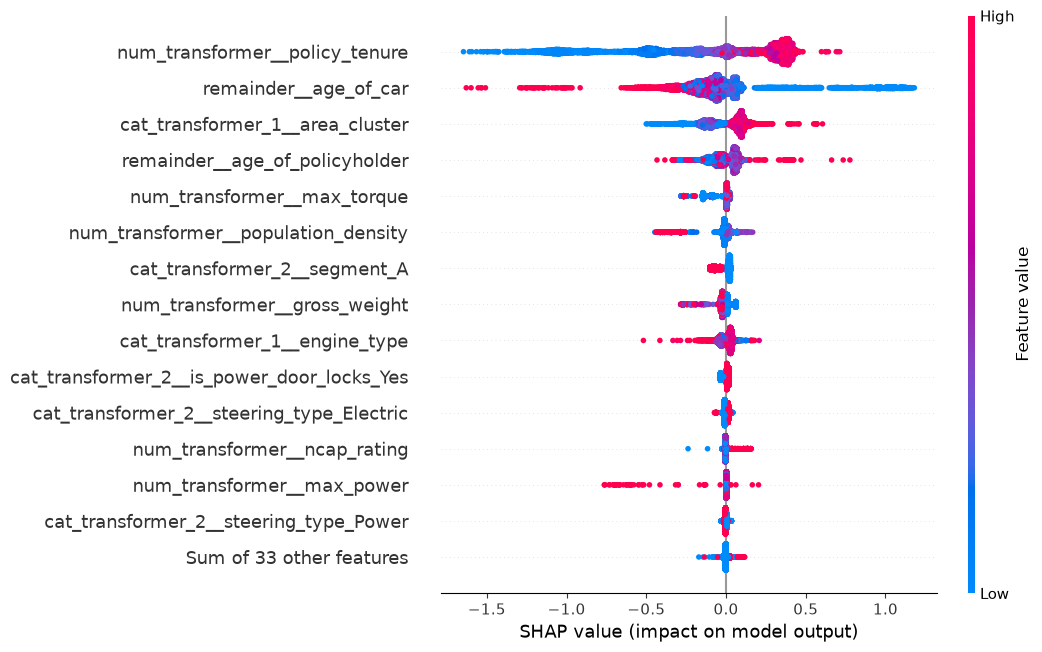

In [ ]:
# empuje que tiene cada feature
# features ordenadas de mayor impacto a menor
# cada punto: una poliza
# posicion horizontal: impacto en prediccion (derecha empuja riesgo hacia arriba, izquierda empuja riesgo hacia abajo)
# color: valor de la feature en esa poliza (rojo alto, azul bajo)

shap.plots.beeswarm(shap_values, max_display=15)

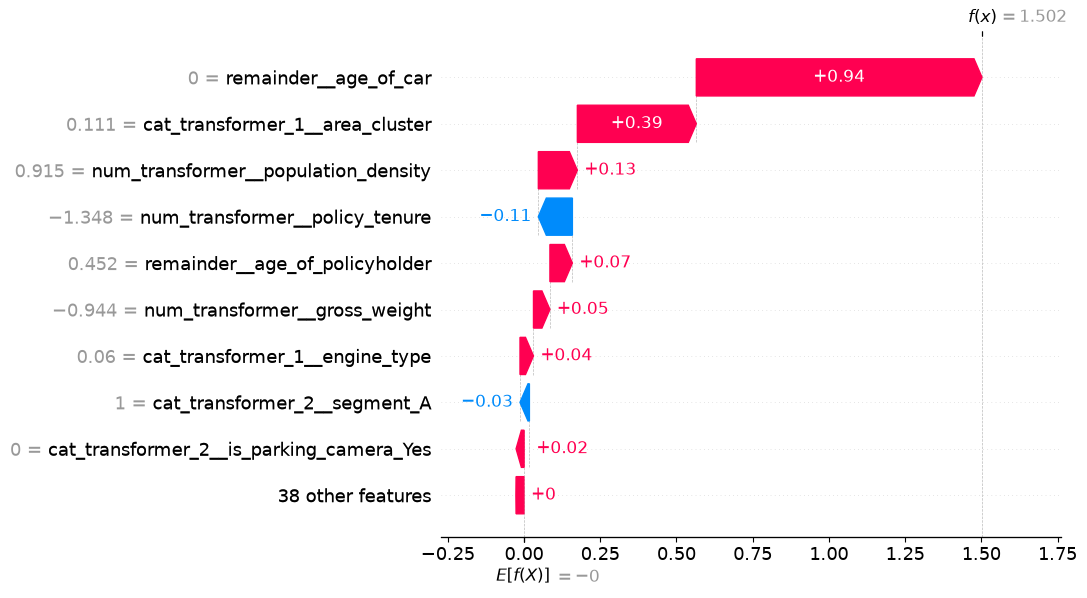

In [ ]:
# explicacion de score en poliza de mayor riesgo en X_test
# tienes que pasar el indice de una poliza en especifico

# f(x) arriba: es el score final: score inicial + valor de cada feature
# f(x) abajo: score inicial
# colores: rojo empuja riesgo arriba, azul empuja riesgo abajo

i_alto = shap_values.values.sum(axis=1).argmax()   # posición de la póliza más riesgosa
shap.plots.waterfall(shap_values[i_alto], max_display=10)

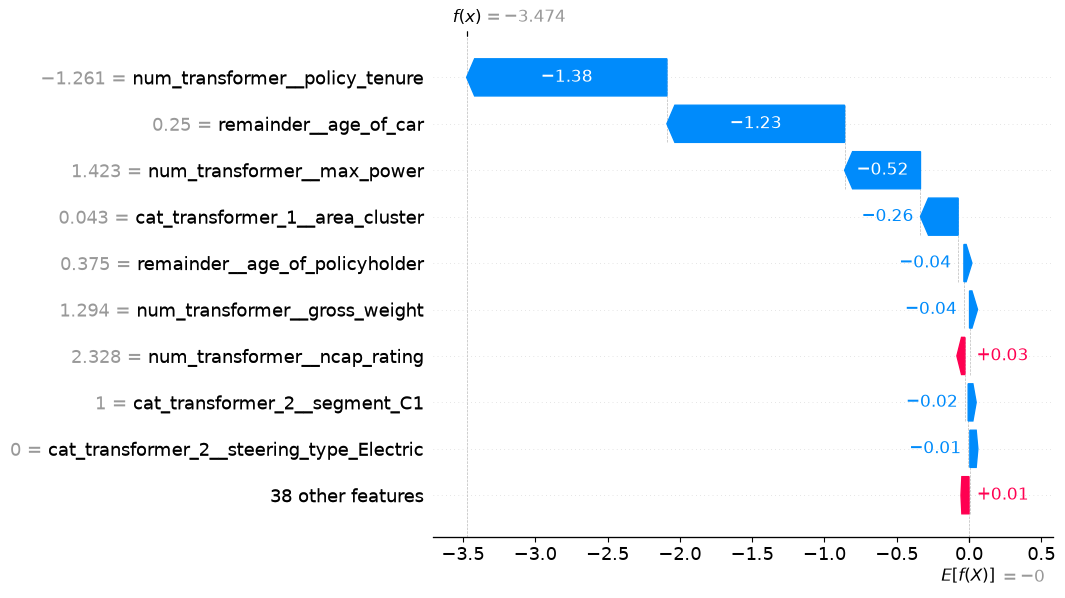

In [84]:
# explicacion de score en poliza de menor riesgo en X_test
i_bajo = shap_values.values.sum(axis=1).argmin()   # posición de la póliza menos riesgosa
shap.plots.waterfall(shap_values[i_bajo], max_display=10)

In [ ]:
# drivers principales del score de una póliza (lo que mostraría Streamlit)

# quitar prefijos: 'num_transformer__policy_tenure' -> 'policy_tenure'
nombres_limpios = [n.split('__')[1] for n in feature_names]

# columnas del one-hot -> variable original: 'segment_C1' -> 'segment'
# recorre las 47 columnas que resultan del preprocessing
# para los casos de ohe con mas de 2 columnas, a cada una le asigna el nombre original
variable_original = []
for n in nombres_limpios:                  # ← loop de AFUERA: los 47 nombres
    for c in X_test.columns:               # ← loop de ADENTRO: las 34 columnas originales
        if n == c or n.startswith(c + '_'):
            variable_original.append(c)
            break

nombres_comunes = {
    'policy_tenure': 'Antigüedad de la póliza',
    'age_of_car': 'Edad del auto',
    'age_of_policyholder': 'Edad del asegurado',
    'area_cluster': 'Zona',
    'population_density': 'Densidad de población',
    'max_power': 'Potencia máxima',
    'max_torque': 'Torque máximo',
    'gross_weight': 'Peso bruto',
    'ncap_rating': 'Estrellas NCAP',
    'segment': 'Segmento',
    'model': 'Modelo',
    'engine_type': 'Tipo de motor',
    'make': 'Fabricante',
    'fuel_type': 'Combustible',
}

def top_drivers(i, n=5):
    """Las n variables que más mueven el score de la póliza i (posición en X_test)."""
    impacto = (
        pd.Series(shap_values.values[i], index=variable_original)
        .groupby(level=0).sum()                       # agrupa por nombre original con el objetivo de sumar las columnas del one-hot de una misma variable
        .sort_values(key=abs, ascending=False)        # ordena por tamaño del empujón, sin importar el signo
        .head(n)
    )
    return pd.DataFrame({
        'variable': [nombres_comunes.get(v, v) for v in impacto.index],
        'valor_ingresado': X_test.iloc[i][impacto.index].values,   # lo que el usuario puso en el formulario
        'impacto': impacto.values.round(2),
        'efecto': np.where(impacto.values > 0, '⬆️ sube el riesgo', '⬇️ baja el riesgo'),
    })

for nombre, i in [('ALTO', i_alto), ('BAJO', i_bajo)]:
    score = shap_values.base_values[i] + shap_values.values[i].sum()
    print(f'Póliza de riesgo {nombre} (score {score:.2f} en log-odds)')
    display(top_drivers(i))

Póliza de riesgo ALTO (score 1.50 en log-odds)


,variable,valor_ingresado,impacto,efecto
0,Edad del auto,0.0,0.94,⬆️ sube el riesgo
1,Zona,C18,0.39,⬆️ sube el riesgo
2,Densidad de población,35036,0.13,⬆️ sube el riesgo
3,Antigüedad de la póliza,0.054464,-0.11,⬇️ baja el riesgo
4,Edad del asegurado,0.451923,0.07,⬆️ sube el riesgo


Póliza de riesgo BAJO (score -3.47 en log-odds)


,variable,valor_ingresado,impacto,efecto
0,Antigüedad de la póliza,0.090681,-1.38,⬇️ baja el riesgo
1,Edad del auto,0.25,-1.23,⬇️ baja el riesgo
2,Potencia máxima,118.36,-0.52,⬇️ baja el riesgo
3,Zona,C9,-0.26,⬇️ baja el riesgo
4,Edad del asegurado,0.375,-0.04,⬇️ baja el riesgo


## Calibración de output 

Nuestros modelos fueron entrenados para no ignorar la clase minoritaria. Esto causa que las predicciones de probabilidad de siniestros esten más infladas de lo normal y que una póliza con un riesgo real de 10% obtenga una predicción mucho más alta.   
Debemos realizar dicha corrección para mostrarle al usuario una probabilidad ajustada a la realidad

In [185]:
(y_train == 0).sum()  / (y_train == 1).sum()

np.float64(14.853884808658679)

In [ ]:
# calcular probabilidades (infladas) en x val
p_inf = model_xgb.predict_proba(X_val)[:, 1]

# proporción de negativos entre positivos con la que se entreno el modelo
# = peso que se le dio a cada positivo en el entrenamiento (= negativos/positivos)
w = (y_train == 0).sum() / (y_train == 1).sum()

# calcular probabilidades ajustadas
odds = p_inf / (1 - p_inf)
p_cal = (odds / w) / (1 + odds / w)

print('PR AUC inflada  :', average_precision_score(y_val, p_inf))
print('PR AUC calibrada:', average_precision_score(y_val, p_cal))
print('Promedio p inflada  :', p_inf.mean())
print('Promedio p calibrada:', p_cal.mean())
print('Tasa real en y_val  :', y_val.mean())

PR AUC inflada  : 0.11878628557231488
PR AUC calibrada: 0.11878628557231488
Promedio p inflada  : 0.4574816
Promedio p calibrada: 0.06133069276402391
Tasa real en y_val  : 0.07054272385936966


In [191]:
p_cal

array([0.03893385, 0.01541211, 0.11702894, ..., 0.07344228, 0.01205312,
       0.11597762], shape=(8789,))

In [ ]:
# Curva de calibración: agrupa pólizas por probabilidad predicha y compara con la tasa real

# ordena las polizas de x_val por su probabilidad ajustada
# divide las polizas de y_val en grupos (10 bins) cada grupo con con la misma cantidad de polizas y una probabilidad de siniestro similar
# para cada grupo calcula:
# 1: el promedio real de siniestros (y=1 / len de grupo)
# 2: el promedio de la probabilidad predicha (ajustada)

frac_real, prob_media = calibration_curve(y_val, p_cal, n_bins=10, strategy='quantile')
pd.DataFrame({'prob_predicha': prob_media.round(3), 'tasa_real': frac_real.round(3)})

,prob_predicha,tasa_real
0,0.015,0.015
1,0.024,0.032
2,0.035,0.050
3,0.045,0.040
4,0.054,0.052
5,0.063,0.085
6,0.072,0.090
7,0.084,0.093
8,0.099,0.111
9,0.122,0.137


La probabilidad ajustada coincide bien con la tasa real en los grupos de menor riesgo. En los de mayor riesgo, el modelo subestima entre 1 y 2 puntos.

## Elección de threshold de Modelo

Una vez comprobado por cuanto debemos ajustar las probabilidades predichas por el modelo, ahora debemos seleccionar un limite a partir del cual el modelo clasifique una póliza como riesgosa o no riesgosa

In [ ]:
# probar porcentajes de pólizas que queremos marcar como riesgosas
# 0.20 significa que queremos marcar el 20% de pólizas con mayor probabilidad ajustada

# precisión baseline si el modelo predijera en base a la proporción de siniestros en validation set
tasa_base = y_val.mean()

# para cada porcentaje de polizas con mayor probabilidad
filas = []
for top in [0.05, 0.10, 0.20, 0.30, 0.50]:
    # se calcula la probabilidad a partir de la cual encontramos ese top (arriba de thr se encuentra el top abajo de thr las demas)
    thr = np.quantile(p_cal, 1 - top)
    # polizas que caen en el top
    marcadas = p_cal >= thr
    # de esas polizas que caen en el top cuantas tuvieron siniestro
    precision = y_val[marcadas].mean()
    # de todos los siniestros, cuantos atrapamos si elejimos el top polizas
    recall = y_val[marcadas].sum() / y_val.sum()
    
    # guardar resultados del threshold
    filas.append({
        'top % polizas con mayor prob': f'{top:.0%}',
        'threshold (p_cal)': round(thr, 3),
        'precision': round(precision, 3),
        'recall': round(recall, 3),
        'lift': round(precision / tasa_base, 2),  # cuántas veces mejor que baseline score
    })


thresholds_df = pd.DataFrame(filas)

In [203]:
y_val.sum()

np.int64(620)

In [198]:
thresholds_df

,top % polizas con mayor prob,threshold (p_cal),precision,recall,lift
0,5%,0.118,0.139,0.098,1.97
1,10%,0.108,0.136,0.194,1.93
2,20%,0.090,0.124,0.352,1.76
3,30%,0.078,0.114,0.484,1.61
4,50%,0.058,0.103,0.732,1.46


Threshold Seleccionado: 0.090
- Elegir un threshold inferior nos daría una ganancia en recall sin embargo nos arriesgariamos a marcar muchas pólizas como riesgosas (el promedio de probabilidad de riesgo es de 6.1%, un threshold de 5.8% marcaria como riesgosa una póliza cuya prbabilidad de riesgo es menor al promedio, lo cual no hace mucho sentido)
- El nivel de precisión obtenida por el modelo no cambia demasiado entre thresholds (va de 10.3% a 13.9%), seleccionando este límite conseguimos 12.4%, es decir una de cada 8 polizas que se predicen como riesgosas obtienen siniestro (vs 1 de cada 14 si se marcarán pólizas al azar)
- Recall obtenido: de todas las pólizas que obtienen siniestro, estamos encontrando 35.2% (218 de 620)
- Elegido sobre los resultados del set de validación

### Predicción Final en Test

In [218]:
risk_thresh = 0.090

# probabilidades infladas 
p_test_inf = model_xgb.predict_proba(X_test)[:,1]

# ajustar probabilidades
odds_test = p_test_inf / (1 - p_test_inf)
p_cal_test = (odds_test / w) / (1 + odds_test / w)

# predicción final con threshold
thresh_array = np.full(len(p_cal_test), risk_thresh)
y_pred = np.where(p_cal_test >= thresh_array, 1, 0)


In [221]:
print(f"score de precisión en test: {precision_score(y_test, y_pred)}")
print(f"score de recall en test: {recall_score(y_test, y_pred)}")
print(f"score f1 en test: {f1_score(y_test, y_pred)}")
print(f"% marcado como riesgoso en test: {y_pred.mean()}")
print(f"Lift en test: {precision_score(y_test, y_pred) / y_test.mean()}")

score de precisión en test: 0.10420168067226891
score de recall en test: 0.3438077634011091
score f1 en test: 0.15993121238177127
% marcado como riesgoso en test: 0.20309477756286268
Lift en test: 1.6928439397940322


### Conclusiones del modelo

**Resultados en test (threshold 0.09, elegido en validación y sin reajustar):**
- Se marcó como riesgoso el 20.3% de las pólizas (en validación fue 20%), así que el threshold fijo se comporta de forma estable con datos nuevos.
- Recall: 34.4% (35.2% en validación). El modelo encuentra la misma proporción de siniestros.
- Precision: 10.4% (12.4% en validación), con un lift de 1.69x sobre marcar pólizas al azar. Es el mismo patrón que el PR-AUC (0.119 en validación vs 0.097 en test): validación fue la muestra "afortunada". Se reporta tal cual.

**Calibración vs. discriminación:**
- **Calibración** responde: ¿las probabilidades son honestas? Sí. Cuando el modelo predice cierta probabilidad para un grupo de pólizas, la tasa real de siniestros de ese grupo es similar.
- **Discriminación** responde: ¿el modelo separa pólizas riesgosas de no riesgosas? Solo de forma moderada. Incluso el grupo más riesgoso tiene una tasa real de ~14%, por lo que la precision al clasificar póliza por póliza tiene un techo bajo.
- A nivel individual, que una póliza tenga siniestro es en gran parte azar: aunque el modelo acierte que el riesgo es 14%, el resultado será 0 la mayoría de las veces. En grupos el azar se promedia y la estimación es confiable.

**Dos usos del mismo modelo:**

| Uso | Pregunta | Desempeño |
|---|---|---|
| Clasificar (threshold 0.09) | ¿Esta póliza tendrá siniestro? | Modesto: precision ~10-12%, lift ~1.7-1.8x |
| Estimar riesgo (probabilidad calibrada) | ¿Cuánto riesgo tiene esta póliza vs. el promedio? | Bueno: calibrado, ~9x de diferencia entre el decil de menor riesgo (1.5%) y el de mayor riesgo (13.7%) |

- El modelo es más útil para **estimar y comparar riesgo entre segmentos** (similar a cómo una aseguradora tarifica) que para predecir qué póliza individual tendrá siniestro.
- Por eso, en la aplicación se mostrará la probabilidad ajustada relativa al promedio (ej. "riesgo estimado 11%, ~1.8x el promedio") además de la clasificación de alto riesgo.
- Hipótesis (no verificada): la separación está limitada porque las variables describen el auto y la póliza, pero no el comportamiento del conductor (kilometraje, historial de accidentes). Una curva de aprendizaje permitiría distinguir si más datos ayudarían o si el límite está en la información disponible.